# Clustering Comparison: K-Means, K-Means++ and DBSCAN

**Student:** Yash Rajput  &nbsp;|&nbsp;  **Registration No:** 2427010652

**Dataset:** EEG Eye State (14 EEG sensor readings per record, plus an eye-state label).

## Aim
To apply three clustering techniques - **K-Means**, **K-Means++** and **DBSCAN** - on the EEG
Eye State data, visualise the groups they form, and compare how well each method separates the
data using inertia and the silhouette score.

## Short background
- **K-Means** splits the data into a chosen number *k* of groups by repeatedly moving *k*
  centroids to the mean of their assigned points. It needs *k* in advance.
- **K-Means++** is not a new algorithm - it is a smarter way of **initialising** the starting
  centroids for K-Means so the result is more stable and usually converges better.
- **DBSCAN** is **density-based**: it grows clusters from dense regions and marks points in
  sparse regions as **noise (label -1)**. It finds the number of clusters on its own.

**Centroid-based vs density-based:** K-Means / K-Means++ assume roughly round, similarly sized
clusters and force every point into one. DBSCAN instead follows the density of points, can find
oddly shaped clusters, and can leave outliers unassigned as noise.

## 1. Import libraries

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

## 2. Load and understand the dataset

In [2]:
df = pd.read_csv("EEG Eye State.csv")

print("Shape:", df.shape)
print("\nColumn names:", list(df.columns))
df.head()

Shape: (14980, 15)

Column names: ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4', 'eyeDetection']


,AF3,F7,F3,FC5,T7,P7,O1,O2,P8,T8,FC6,F4,F8,AF4,eyeDetection
0,4329.23,4009.23,4289.23,4148.21,4350.26,4586.15,4096.92,4641.03,4222.05,4238.46,4211.28,4280.51,4635.90,4393.85,0
1,4324.62,4004.62,4293.85,4148.72,4342.05,4586.67,4097.44,4638.97,4210.77,4226.67,4207.69,4279.49,4632.82,4384.10,0
2,4327.69,4006.67,4295.38,4156.41,4336.92,4583.59,4096.92,4630.26,4207.69,4222.05,4206.67,4282.05,4628.72,4389.23,0
3,4328.72,4011.79,4296.41,4155.90,4343.59,4582.56,4097.44,4630.77,4217.44,4235.38,4210.77,4287.69,4632.31,4396.41,0
4,4326.15,4011.79,4292.31,4151.28,4347.69,4586.67,4095.90,4627.69,4210.77,4244.10,4212.82,4288.21,4632.82,4398.46,0


In [3]:
print("Data types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Data types:
AF3             float64
F7              float64
F3              float64
FC5             float64
T7              float64
P7              float64
O1              float64
O2              float64
P8              float64
T8              float64
FC6             float64
F4              float64
F8              float64
AF4             float64
eyeDetection      int64
dtype: object

Missing values per column:
AF3             0
F7              0
F3              0
FC5             0
T7              0
P7              0
O1              0
O2              0
P8              0
T8              0
FC6             0
F4              0
F8              0
AF4             0
eyeDetection    0
dtype: int64

Duplicate rows: 0


**Understanding the columns**

All 14 columns `AF3 ... AF4` are numeric EEG sensor voltages - these are the features we will
cluster on. The last column `eyeDetection` is a 0/1 **label** (eye closed / open). Clustering is
*unsupervised*, so we **do not** feed the label into the algorithms; we keep it aside only to
see, at the end, whether the discovered groups line up with the real eye state.

There are no missing values and no duplicate rows, so no imputation or de-duplication is needed.

In [4]:
feature_cols = [c for c in df.columns if c != "eyeDetection"]
print("Feature (numerical) columns used for clustering:")
print(feature_cols)
print("\nLabel column kept aside:", "eyeDetection")
print("\nClass balance of the label:", df["eyeDetection"].value_counts().to_dict())

Feature (numerical) columns used for clustering:
['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']

Label column kept aside: eyeDetection

Class balance of the label: {0: 8257, 1: 6723}


## 3. Data preprocessing

**Extreme outliers.** EEG recordings contain a few sensor glitches with impossible values (some
readings jump to several hundred thousand while the normal range is ~4000). We remove rows where
any feature is more than 10 standard deviations from its mean. Only a handful of rows are
affected, but because clustering uses distances, leaving them in would distort every result.

In [5]:
z = (df[feature_cols] - df[feature_cols].mean()) / df[feature_cols].std()
mask_keep = (z.abs() <= 10).all(axis=1)

df_clean = df[mask_keep].reset_index(drop=True)
print("Rows removed as extreme outliers:", (~mask_keep).sum())
print("Shape after cleaning:", df_clean.shape)

Rows removed as extreme outliers: 4
Shape after cleaning: (14976, 15)


**Scaling.** The sensors have different baselines and spreads, and distance-based clustering is
sensitive to scale, so we standardise every feature to mean 0 and standard deviation 1 with
`StandardScaler`. We keep `df_clean` (original units) for interpreting the clusters later.

In [6]:
X_original = df_clean[feature_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_original)
print("Scaled feature matrix shape:", X_scaled.shape)

Scaled feature matrix shape: (14976, 14)


**PCA for visualisation only.** The data has 14 features, which we cannot plot directly. We use
PCA to project it to 2 dimensions *for plotting*. Clustering itself is still done on all 14
scaled features - the PCA plot is only a lower-dimensional picture of the result.

In [7]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by the 2 PCA components:",
      pca.explained_variance_ratio_.round(3),
      "| total:", round(pca.explained_variance_ratio_.sum(), 3))

Variance explained by the 2 PCA components: [0.593 0.152] | total: 0.745


## 4. K-Means clustering

### 4.1 Choose k with the Elbow Method
We fit K-Means for a range of *k* and plot the **inertia** (within-cluster sum of squares). The
"elbow", where the curve stops dropping steeply, suggests a reasonable *k*.

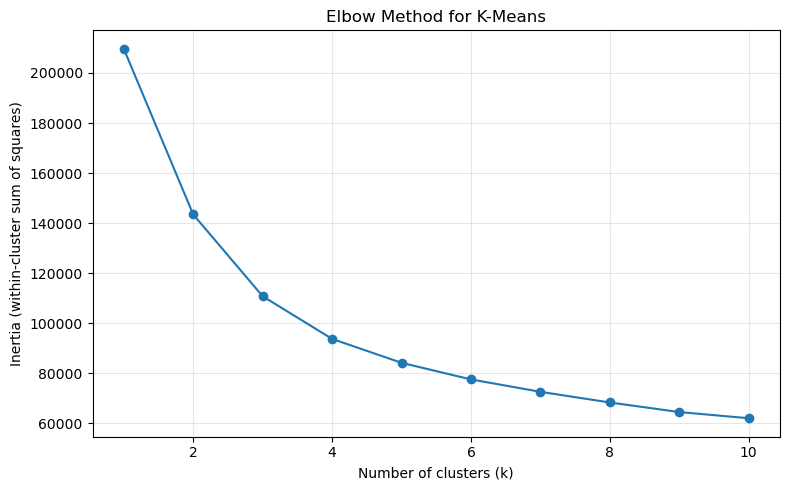

In [8]:
inertias = []
k_range = range(1, 11)
for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.title("Elbow Method for K-Means")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
print("Silhouette score by k:")
for k in range(2, 7):
    km = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=10)
    lab = km.fit_predict(X_scaled)
    print(f"  k={k}: silhouette = {silhouette_score(X_scaled, lab):.3f}")

Silhouette score by k:


  k=2: silhouette = 0.507


  k=3: silhouette = 0.280


  k=4: silhouette = 0.234


  k=5: silhouette = 0.189


  k=6: silhouette = 0.171


The elbow bends sharply at **k = 2** and k = 2 also gives the highest silhouette score, so we
use **k = 2**. (This also matches the data having two natural eye states.)

In [10]:
k = 2
kmeans = KMeans(n_clusters=k, init="random", n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means (init='random')")
print("  Inertia        :", round(kmeans.inertia_, 1))
print("  Iterations      :", kmeans.n_iter_)
print("  Silhouette score:", round(silhouette_score(X_scaled, kmeans_labels), 3))
print("  Cluster sizes   :", pd.Series(kmeans_labels).value_counts().sort_index().to_dict())

K-Means (init='random')
  Inertia        : 143470.3
  Iterations      : 11


  Silhouette score: 0.507
  Cluster sizes   : {0: 1795, 1: 13181}


### 4.2 Visualise the K-Means clusters (PCA projection)

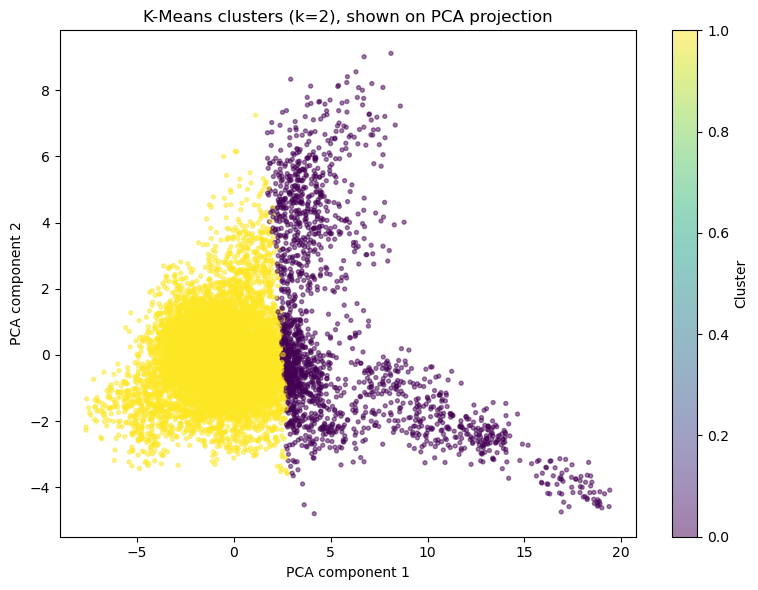

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="viridis", s=8, alpha=0.5)
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("K-Means clusters (k=2), shown on PCA projection")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

## 5. K-Means++ clustering

K-Means++ uses the same algorithm but a smarter initialisation (`init="k-means++"`). We run it
on the **same features, scaling and k** so the two are directly comparable.

In [12]:
kmeanspp = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
kmeanspp_labels = kmeanspp.fit_predict(X_scaled)

print("K-Means++ (init='k-means++')")
print("  Inertia        :", round(kmeanspp.inertia_, 1))
print("  Iterations      :", kmeanspp.n_iter_)
print("  Silhouette score:", round(silhouette_score(X_scaled, kmeanspp_labels), 3))
print("  Cluster sizes   :", pd.Series(kmeanspp_labels).value_counts().sort_index().to_dict())

K-Means++ (init='k-means++')
  Inertia        : 143470.3
  Iterations      : 29


  Silhouette score: 0.507
  Cluster sizes   : {0: 13181, 1: 1795}


**Observation.** On this dataset both initialisations reach the **same final clusters** - the
inertia and silhouette score are identical, because the two-group structure is strong enough
that the starting points do not change the outcome. In general K-Means++ is still preferred
because it spreads the initial centroids out and avoids poor random starts, which matters more
when *k* is larger or the clusters are less obvious.

## 6. DBSCAN clustering

DBSCAN needs two parameters:
- **eps** - how close two points must be to count as neighbours.
- **min_samples** - how many neighbours a point needs to sit in a dense region.

### 6.1 Choose eps with a k-distance graph
We sort every point by the distance to its `min_samples`-th nearest neighbour; the "knee" of the
curve is a good `eps`.

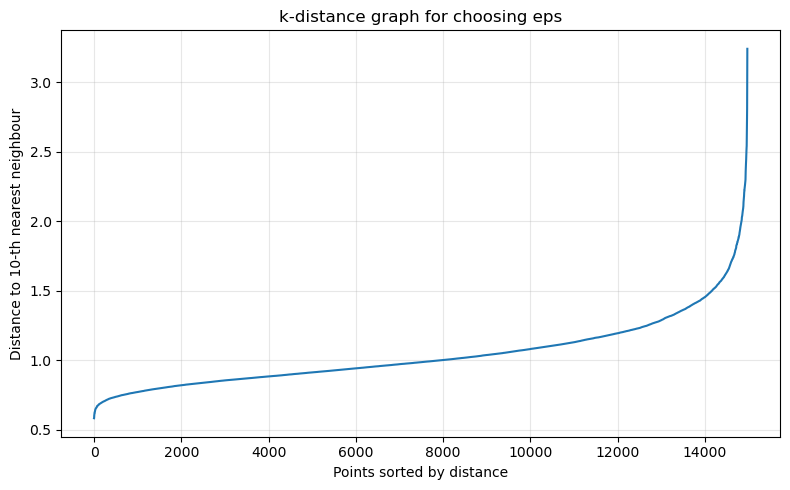

In [13]:
min_samples = 10
neigh = NearestNeighbors(n_neighbors=min_samples)
neigh.fit(X_scaled)
distances, _ = neigh.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_dist)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}-th nearest neighbour")
plt.title("k-distance graph for choosing eps")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The curve turns upward around a distance of **1.5**, so we use `eps = 1.5` with
`min_samples = 10`.

In [14]:
eps = 1.5
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int((dbscan_labels == -1).sum())

print("DBSCAN (eps =", eps, ", min_samples =", min_samples, ")")
print("  Clusters found :", n_clusters_db)
print("  Noise points   :", n_noise)
print("  Cluster sizes (-1 = noise):")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN (eps = 1.5 , min_samples = 10 )
  Clusters found : 8
  Noise points   : 228
  Cluster sizes (-1 = noise):
-1      228
 0    14514
 1       10
 2       15
 3        8
 4      158
 5       18
 6       13
 7       12
Name: count, dtype: int64


In [15]:
mask = dbscan_labels != -1
if n_clusters_db >= 2 and mask.sum() > n_clusters_db:
    db_sil = silhouette_score(X_scaled[mask], dbscan_labels[mask])
    print("Silhouette score (noise excluded):", round(db_sil, 3))
else:
    db_sil = None
    print("Silhouette score not valid (need >= 2 clusters with enough points).")

Silhouette score (noise excluded): 0.103


### 6.2 Visualise the DBSCAN result (PCA projection)

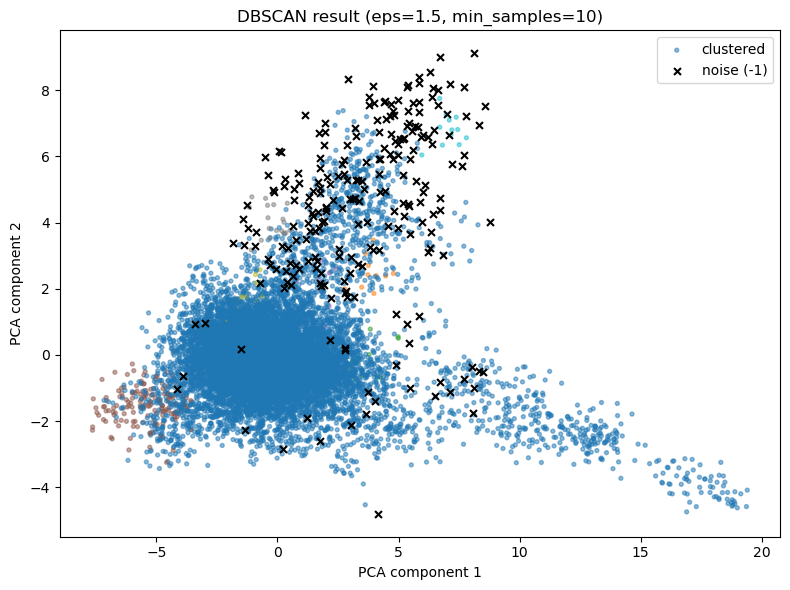

In [16]:
plt.figure(figsize=(8, 6))
noise = dbscan_labels == -1
plt.scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=dbscan_labels[~noise],
            cmap="tab10", s=8, alpha=0.5, label="clustered")
plt.scatter(X_pca[noise, 0], X_pca[noise, 1], c="black", marker="x", s=25, label="noise (-1)")
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title(f"DBSCAN result (eps={eps}, min_samples={min_samples})")
plt.legend()
plt.tight_layout()
plt.show()

**Why DBSCAN differs from K-Means here.** K-Means was told to make exactly 2 clusters, so it
splits the data cleanly in two. DBSCAN decides on its own based on density: in 14 dimensions the
points form one large, fairly uniform dense region, so DBSCAN puts almost everything into one
dominant cluster, peels off a few small dense pockets, and labels the sparse edge points as
noise. This is the expected behaviour of a density method on high-dimensional data where
distances become similar for most pairs of points.

## 7. Evaluation and comparison

In [17]:
def safe_sil(labels):
    m = np.array(labels) != -1
    uniq = set(np.array(labels)[m])
    if len(uniq) >= 2 and m.sum() > len(uniq):
        return round(silhouette_score(X_scaled[m], np.array(labels)[m]), 3)
    return None

comparison = pd.DataFrame([
    {"Algorithm": "K-Means (random init)",
     "Clusters": k, "Noise": 0,
     "Inertia": round(kmeans.inertia_, 1),
     "Silhouette": round(silhouette_score(X_scaled, kmeans_labels), 3),
     "Observation": "2 clear groups, every point assigned"},
    {"Algorithm": "K-Means++",
     "Clusters": k, "Noise": 0,
     "Inertia": round(kmeanspp.inertia_, 1),
     "Silhouette": round(silhouette_score(X_scaled, kmeanspp_labels), 3),
     "Observation": "same solution as random init here"},
    {"Algorithm": "DBSCAN",
     "Clusters": n_clusters_db, "Noise": n_noise,
     "Inertia": None,
     "Silhouette": safe_sil(dbscan_labels),
     "Observation": "one dominant cluster + small pockets + noise"},
])
comparison

,Algorithm,Clusters,Noise,Inertia,Silhouette,Observation
0,K-Means (random init),2,0,143470.3,0.507,"2 clear groups, every point assigned"
1,K-Means++,2,0,143470.3,0.507,same solution as random init here
2,DBSCAN,8,228,NaN,0.103,one dominant cluster + small pockets + noise


**Notes on the table**
- **Inertia** is only defined for K-Means-type methods, so it is left blank for DBSCAN; also it
  should not be compared between K-Means and DBSCAN because they optimise different things.
- The DBSCAN **silhouette** is computed only on the clustered points (noise excluded). It is
  still dominated by the single huge cluster, so it is not directly comparable to the K-Means
  value.
- Clustering has **no ground-truth accuracy** unless reliable labels exist. We kept
  `eyeDetection` aside and can optionally check how the K-Means groups line up with it below, but
  this is a cross-check, not a training signal.

In [18]:
crosstab = pd.crosstab(kmeans_labels, df_clean["eyeDetection"],
                       rownames=["K-Means cluster"], colnames=["eyeDetection"])
print("K-Means clusters vs actual eye state:")
print(crosstab)

K-Means clusters vs actual eye state:
eyeDetection        0     1
K-Means cluster            
0                 849   946
1                7405  5776


## 8. Results and observations

- **K-Means and K-Means++** both found the same **two clusters** with a solid silhouette score
  (~0.51) and split the data cleanly. On this dataset the smarter K-Means++ initialisation did
  not change the final clusters because the two-group structure is strong.
- **DBSCAN** did **not** reproduce that clean 2-way split. With a density view of 14-dimensional
  data it grouped almost all points into one big cluster, found a few tiny dense pockets, and
  marked the sparse points as noise. Its silhouette is low and is skewed by the dominant cluster.
- **Strengths/weaknesses seen here:** K-Means is simple and gives clear, balanced groups when we
  know *k*, but it forces every point into a cluster. DBSCAN needs no *k* and can flag outliers,
  but it struggled with this high-dimensional data where densities are similar everywhere.
- For *this* dataset, **K-Means / K-Means++ gave the more useful and interpretable result.**

## 9. Conclusion

Three clustering methods were applied to the EEG Eye State data after removing a few extreme
sensor glitches and standardising the features. K-Means and K-Means++ both produced the same two
well-separated clusters, confirming that K-Means++ changes only the *initialisation*, not the
algorithm, and gives the same answer when the structure is clear. DBSCAN, being density-based,
chose its own clusters and instead returned one dominant group plus noise, showing how a density
method behaves differently from a centroid method - especially in many dimensions. Overall,
centroid-based clustering suited this dataset better, while DBSCAN's main value was in flagging
outlier points rather than producing balanced groups.